# FX smile risk: delta pillars
Quotes ATM (DNS), RR25, BF25, RR10, BF10; exact SVI fit to the five pillars. Log: `smile_risk_log.md`.

In [1]:
"""FX-style quotes (ATM DNS, 25d/10d RR and BF) vs strike-grid quotes: how diffuse are the bucketed vegas?

Conventions (simplified, stated in the output):
- forward delta, premium-unadjusted; ATM = delta-neutral straddle, K = F exp(sigma^2 T / 2)
- pillar vols: s_25C = ATM + BF25 + RR25/2, s_25P = ATM + BF25 - RR25/2 (smile-strangle convention), same for 10d
- SVI in total variance against z = log(K/F)
"""
import numpy as np
import matplotlib.pyplot as mpl
from scipy.optimize import least_squares, brentq
from scipy.stats import norm

T, S0, rd, rf = 1.0, 100.0, 0.04, 0.02
F = S0 * np.exp((rd - rf) * T)
DF = np.exp(-rd * T)
q0 = np.array([0.10, -0.015, 0.0035, -0.028, 0.012])  # ATM, RR25, BF25, RR10, BF10
QN = ["DN", "RR25", "BF25", "RR10", "BF10"]
PN = ["10P", "25P", "DN", "25C", "10C"]

# pillar vols from quotes: sigma = M q
M = np.array([
    [1, 0, 0, -0.5, 1],   # 10P
    [1, -0.5, 1, 0, 0],   # 25P
    [1, 0, 0, 0, 0],      # ATM
    [1, 0.5, 1, 0, 0],    # 25C
    [1, 0, 0, 0.5, 1],    # 10C
], dtype=float)


def svi(z, P):
    a, b, r, m, s = P
    u = z - m
    return a + b * (r * u + np.sqrt(u * u + s * s))


def svi_jac(z, P):
    _, b, r, m, s = P
    u = z - m; q = np.sqrt(u * u + s * s)
    return np.column_stack([np.ones_like(z), r * u + q, b * u, -b * (r + u / q), b * s / q])


def strike_from_delta(delta, sig, call):
    # forward delta, unadjusted: call N(d1) = delta, put N(d1) - 1 = -delta
    d1 = norm.ppf(delta) if call else -norm.ppf(delta)
    return F * np.exp(-d1 * sig * np.sqrt(T) + 0.5 * sig * sig * T)


def pillar_strikes(sig):
    return np.array([
        strike_from_delta(0.10, sig[0], False),
        strike_from_delta(0.25, sig[1], False),
        F * np.exp(0.5 * sig[2] ** 2 * T),
        strike_from_delta(0.25, sig[3], True),
        strike_from_delta(0.10, sig[4], True),
    ])


def fit(z, w, guess, tight=True):
    lo = (-np.inf, 1e-6, -0.999, -np.inf, 1e-4); hi = (np.inf, np.inf, 0.999, np.inf, 10)
    tol = dict(xtol=1e-15, ftol=1e-15, gtol=1e-15) if tight else {}
    res = least_squares(lambda P: svi(z, P) - w, guess, jac=lambda P: svi_jac(z, P), bounds=(lo, hi), **tol)
    return res.x


def black(K, sig):
    d1 = (np.log(F / K) + 0.5 * sig * sig * T) / (sig * np.sqrt(T))
    return DF * (F * norm.cdf(d1) - K * norm.cdf(d1 - sig * np.sqrt(T)))


def bs_vega(K, sig):
    d1 = (np.log(F / K) + 0.5 * sig * sig * T) / (sig * np.sqrt(T))
    return DF * F * np.sqrt(T) * norm.pdf(d1)


def price_from_P(P, K):
    return black(K, np.sqrt(svi(np.log(K / F), P) / T))


# ---------- base FX smile
sig0 = M @ q0
K0 = pillar_strikes(sig0)
z0 = np.log(K0 / F)
P0 = fit(z0, T * sig0**2, np.array([0.005, 0.01, -0.2, 0.0, 0.2]))
print("FX pillars:", dict(zip(PN, np.round(K0, 2))), "vols", np.round(sig0, 4))
print("SVI params", np.round(P0, 5), "fit max err", np.abs(svi(z0, P0) - T * sig0**2).max(),
      "min var", P0[0] + P0[1] * P0[4] * np.sqrt(1 - P0[2]**2))


def fx_price(q, K, P_guess=P0, fixed_strikes=False):
    sig = M @ q
    Kp = K0 if fixed_strikes else pillar_strikes(sig)
    P = fit(np.log(Kp / F), T * sig**2, P_guess)
    return price_from_P(P, K)


def fd(fun, x, h=1e-6):
    return np.array([(fun(x + h * e) - fun(x - h * e)) / (2 * h) for e in np.eye(len(x))])


# option strikes: fixed after trade, at these deltas of the base smile
opt_d = [("5P", 0.05, False), ("10P", 0.10, False), ("25P", 0.25, False), ("40P", 0.40, False), ("ATM", None, None),
         ("40C", 0.40, True), ("25C", 0.25, True), ("10C", 0.10, True), ("5C", 0.05, True)]


def strike_on_smile(delta, call):
    if delta is None:
        return brentq(lambda K: K - F * np.exp(0.5 * svi(np.log(K / F), P0) / T * T), 0.5 * F, 2 * F)
    def g(K):
        s = np.sqrt(svi(np.log(K / F), P0) / T)
        d1 = (np.log(F / K) + 0.5 * s * s * T) / (s * np.sqrt(T))
        return (norm.cdf(d1) - delta) if call else (norm.cdf(d1) - 1 + delta)
    return brentq(g, 0.3 * F, 3 * F)


opts = [(n, strike_on_smile(d, c)) for n, d, c in opt_d]

IMG = "/Users/ptamarov/ptamarov.github.io/posts/images/"
mpl.rcParams.update({
    "font.size": 12, "axes.titlesize": 13, "axes.labelsize": 12,
    "xtick.labelsize": 11, "ytick.labelsize": 11, "legend.fontsize": 11,
    "lines.linewidth": 1.8, "grid.linestyle": "dashed", "grid.alpha": 0.6,
})

FX pillars: {'10P': np.float64(87.5), '25P': np.float64(95.25), 'DN': np.float64(102.53), '25C': np.float64(109.35), '10C': np.float64(116.23)} vols [0.126 0.111 0.1   0.096 0.098]
SVI params [ 0.00515  0.03821 -0.30081  0.03926  0.1115 ] fit max err 1.734723475976807e-18 min var 0.00921212404016675


In [2]:
# buckets per option: pillar-vol basis and quote basis, normalised by flat vega (= the ATM quote bucket)
for n, K in opts:
    vq = fd(lambda q: fx_price(q, K), q0)
    vp = np.linalg.solve(M.T, vq)
    print(f"{n:>4} K={K:7.2f} flat {vq[0]:7.3f} | pillars {np.round(vp / vq[0], 3)} gross/net {np.abs(vp).sum() / vp.sum():5.2f}"
          f" | quotes {np.round(vq / vq[0], 3)}")

  5P K=  82.23 flat   7.525 | pillars [ 2.201 -2.023  1.194 -0.471  0.1  ] gross/net  5.99 | quotes [ 1.     0.776 -2.494 -1.051  2.301]
 10P K=  87.50 flat  13.686 | pillars [ 1.  0.  0.  0. -0.] gross/net  1.00 | quotes [ 1.   0.   0.  -0.5  1. ]
 25P K=  95.25 flat  28.138 | pillars [ 0.  1. -0.  0.  0.] gross/net  1.00 | quotes [ 1.  -0.5  1.   0.   0. ]
 40P K=  99.92 flat  37.057 | pillars [-0.066  0.42   0.748 -0.122  0.021] gross/net  1.38 | quotes [ 1.    -0.271  0.298  0.044 -0.045]
 ATM K= 102.53 flat  39.549 | pillars [0. 0. 1. 0. 0.] gross/net  1.00 | quotes [1. 0. 0. 0. 0.]
 40C K= 105.08 flat  38.876 | pillars [ 0.05  -0.218  0.88   0.327 -0.039] gross/net  1.51 | quotes [ 1.     0.273  0.11  -0.044  0.01 ]
 25C K= 109.35 flat  31.341 | pillars [ 0.  0. -0.  1.  0.] gross/net  1.00 | quotes [1.  0.5 1.  0.  0. ]
 10C K= 116.23 flat  15.666 | pillars [-0. -0.  0. -0.  1.] gross/net  1.00 | quotes [ 1.   0.  -0.   0.5  1. ]
  5C K= 121.11 flat   8.561 | pillars [ 0.433 -1.

K=80: h=[ 2.865 -3.192  1.962 -0.825  0.19 ] sum|h|=9.03
K=85: h=[ 1.539 -0.855  0.459 -0.184  0.042] sum|h|=3.08
K=100: h=[-0.065  0.409  0.76  -0.127  0.024] sum|h|=1.39
K=105: h=[ 0.049 -0.215  0.882  0.327 -0.043] sum|h|=1.52
K=120: h=[ 0.258 -0.921  1.556 -1.916  2.023] sum|h|=6.68
K=125: h=[ 0.861 -3.026  4.92  -5.434  3.679] sum|h|=17.92


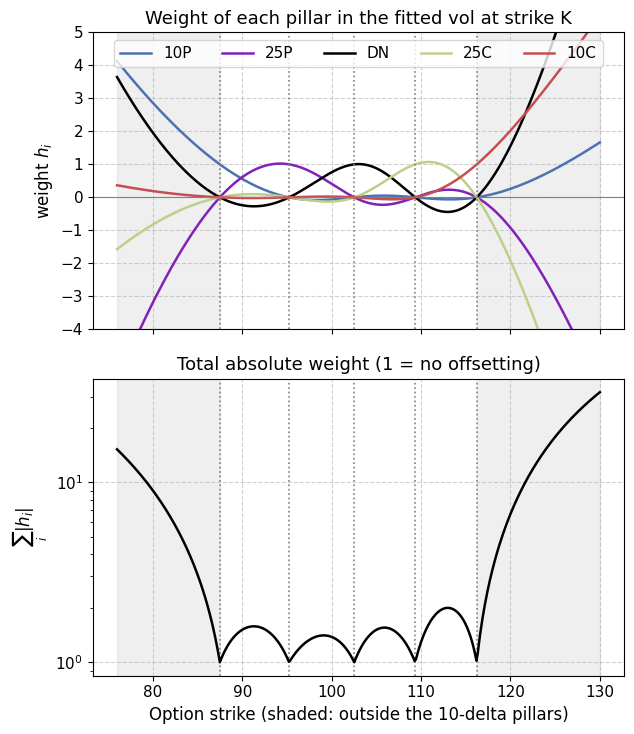

In [3]:
# weights h_i(K) of the exact fit (fixed pillar strikes): h = J^{-T} j*
J = svi_jac(z0, P0)
Ks = np.linspace(76, 130, 400)
H = np.array([np.linalg.solve(J.T, svi_jac(np.array([np.log(K / F)]), P0)[0]) for K in Ks])
for K in [80, 85, 100, 105, 120, 125]:
    h = np.linalg.solve(J.T, svi_jac(np.array([np.log(K / F)]), P0)[0])
    print(f"K={K}: h={np.round(h, 3)} sum|h|={np.abs(h).sum():.2f}")

colors = ["#4C72B0", "#8320B8", "k", "#BDD089", "#C44E52"]
fig, ax = mpl.subplots(2, 1, figsize=(6.5, 7.5), sharex=True)
for i in range(5):
    ax[0].plot(Ks, H[:, i], color=colors[i], label=PN[i])
    ax[1].axvline(K0[i], color="grey", ls="dotted", lw=1.2)
    ax[0].axvline(K0[i], color="grey", ls="dotted", lw=1.2)
for a in ax:
    a.axvspan(Ks[0], K0[0], color="grey", alpha=0.12); a.axvspan(K0[-1], Ks[-1], color="grey", alpha=0.12); a.grid()
ax[0].axhline(0, color="grey", lw=0.8); ax[0].set_ylim(-4, 5)
ax[0].set_ylabel("weight $h_i$"); ax[0].set_title("Weight of each pillar in the fitted vol at strike K"); ax[0].legend(ncol=5, loc="upper center")
ax[1].semilogy(Ks, np.abs(H).sum(axis=1), color="k")
ax[1].set_ylabel(r"$\sum_i |h_i|$"); ax[1].set_title("Total absolute weight (1 = no offsetting)")
ax[1].set_xlabel("Option strike (shaded: outside the 10-delta pillars)")
fig.tight_layout(); fig.savefig(IMG + "202612_fx_h.svg", bbox_inches="tight"); mpl.show()

In [4]:
# delta pillars: strikes move with vols. IFT term 2 T sigma_k -> 2 T sigma_k - f_z(z_k) dz_k/dsigma_k
def fz(z, P):
    _, b, r, m, s = P; u = z - m
    return b * (r + u / np.sqrt(u * u + s * s))
def dz_dsig(k, sig, h=1e-7):
    e = np.zeros(5); e[k] = h
    return (np.log(pillar_strikes(sig + e)[k] / F) - np.log(pillar_strikes(sig - e)[k] / F)) / (2 * h)
eff = np.array([2 * T * sig0[k] - fz(z0[k], P0) * dz_dsig(k, sig0) for k in range(5)])
for n, K in opts:
    zs = np.log(K / F); sig = np.sqrt(svi(np.array([zs]), P0)[0] / T)
    dV = bs_vega(K, sig) / (2 * T * sig) * svi_jac(np.array([zs]), P0)[0]
    v_ift = np.linalg.solve(J.T, dV) * eff
    v_bump = np.linalg.solve(M.T, fd(lambda q: fx_price(q, K), q0))
    v_fix = np.linalg.solve(M.T, fd(lambda q: fx_price(q, K, fixed_strikes=True), q0))
    print(f"{n:>4}: flat (delta pillars) {v_bump.sum():7.3f} | fixed-K pillars {v_fix.sum():7.3f} | BS {bs_vega(K, sig):7.3f}"
          f" | max|IFT - bump| {np.abs(v_ift - v_bump).max():.1e}")

  5P: flat (delta pillars)   7.525 | fixed-K pillars  10.146 | BS  10.109 | max|IFT - bump| 8.1e-06
 10P: flat (delta pillars)  13.686 | fixed-K pillars  17.202 | BS  17.202 | max|IFT - bump| 2.0e-08
 25P: flat (delta pillars)  28.138 | fixed-K pillars  31.148 | BS  31.148 | max|IFT - bump| 1.1e-07
 40P: flat (delta pillars)  37.057 | fixed-K pillars  37.882 | BS  37.869 | max|IFT - bump| 9.7e-07
 ATM: flat (delta pillars)  39.549 | fixed-K pillars  39.104 | BS  39.104 | max|IFT - bump| 4.2e-09
 40C: flat (delta pillars)  38.876 | fixed-K pillars  37.856 | BS  37.869 | max|IFT - bump| 2.1e-07
 25C: flat (delta pillars)  31.341 | fixed-K pillars  31.148 | BS  31.148 | max|IFT - bump| 2.1e-07
 10C: flat (delta pillars)  15.666 | fixed-K pillars  17.202 | BS  17.202 | max|IFT - bump| 5.2e-08
  5C: flat (delta pillars)   8.561 | fixed-K pillars  10.081 | BS  10.109 | max|IFT - bump| 3.3e-05


K=90: formula [ 0.826  -0.2182  0.5775 -0.2385  0.4483]  fd [ 0.826  -0.2182  0.5775 -0.2385  0.4483]
K=100: formula [ 0.9798 -0.2582  0.2785  0.042  -0.0432]  fd [ 0.9798 -0.2582  0.2785  0.042  -0.0432]
K=105: formula [ 1.0264  0.2722  0.1027 -0.0447  0.0111]  fd [ 1.0264  0.2722  0.1027 -0.0447  0.0111]
K=112: formula [0.9727 0.407  1.2424 0.1353 0.157 ]  fd [0.9727 0.407  1.2424 0.1353 0.157 ]
K=120: formula [ 0.8602 -0.4619 -2.7638  0.7704  2.0561]  fd [ 0.8602 -0.4619 -2.7638  0.7704  2.0561]


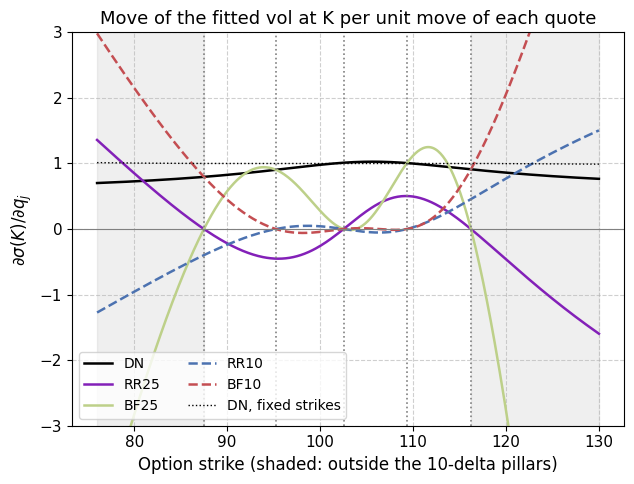

In [5]:
# quote-basis weights: d sigma(K) / d q_j for q = (ATM, RR25, BF25, RR10, BF10), delta pillars (strikes move)
# d sigma(K)/d sigma_k = h_k * eff_k / (2 T sigma(K)),  then quote basis = M^T (pillar basis)
def dsig_dq(K, eff_k):
    zs = np.log(K / F); sigK = np.sqrt(svi(np.array([zs]), P0)[0] / T)
    h = np.linalg.solve(J.T, svi_jac(np.array([zs]), P0)[0])
    return M.T @ (h * eff_k / (2 * T * sigK))

fixed = 2 * T * sig0  # pillars at fixed strikes
Ks = np.linspace(76, 130, 400)
Gd = np.array([dsig_dq(K, eff) for K in Ks]); Gf = np.array([dsig_dq(K, fixed) for K in Ks])

# check against finite differences of the fitted vol through the whole chain quotes -> strikes -> fit
def fitted_vol(q, K):
    sig = M @ q; P = fit(np.log(pillar_strikes(sig) / F), T * sig**2, P0)
    return np.sqrt(svi(np.array([np.log(K / F)]), P)[0] / T)
for K in [90, 100, 105, 112, 120]:
    print(f"K={K}: formula {np.round(dsig_dq(K, eff), 4)}  fd {np.round(fd(lambda q: fitted_vol(q, K), q0), 4)}")

labels = ["DN", "RR25", "BF25", "RR10", "BF10"]
colors = ["k", "#8320B8", "#BDD089", "#4C72B0", "#C44E52"]
fig, ax = mpl.subplots(figsize=(6.5, 5))
for j in range(5):
    ax.plot(Ks, Gd[:, j], color=colors[j], label=labels[j], ls="-" if j in (0, 1, 2) else "--")
ax.plot(Ks, Gf[:, 0], color="k", lw=1, ls="dotted", label="DN, fixed strikes")
for k in K0: ax.axvline(k, color="grey", ls="dotted", lw=1.2)
ax.axvspan(Ks[0], K0[0], color="grey", alpha=0.12); ax.axvspan(K0[-1], Ks[-1], color="grey", alpha=0.12)
ax.axhline(0, color="grey", lw=0.8); ax.set_ylim(-3, 3); ax.grid()
ax.set_xlabel("Option strike (shaded: outside the 10-delta pillars)")
ax.set_ylabel(r"$\partial \sigma(K) / \partial q_j$")
ax.set_title("Move of the fitted vol at K per unit move of each quote")
ax.legend(ncol=2, fontsize=10, loc="lower left")
fig.tight_layout(); fig.savefig(IMG + "202612_fx_hq.svg", bbox_inches="tight"); mpl.show()

In [6]:
# the exact fit follows every quote move: one-pillar bumps, density check
Kf = np.linspace(70, 140, 4000)
def min_density(P):
    sig = np.sqrt(np.maximum(svi(np.log(Kf / F), P), 1e-12) / T)
    d1 = (np.log(F / Kf) + 0.5 * sig**2 * T) / (sig * np.sqrt(T))
    C = F * norm.cdf(d1) - Kf * norm.cdf(d1 - sig * np.sqrt(T))
    return np.gradient(np.gradient(C, Kf), Kf).min()
print("base min density", min_density(P0))
for bp in [10, 25, 50]:
    bad = []
    for k in range(5):
        for sg in (1, -1):
            sig = sig0.copy(); sig[k] += sg * bp * 1e-4
            if min_density(fit(np.log(pillar_strikes(sig) / F), T * sig**2, P0)) < 0:
                bad.append(("+" if sg > 0 else "-") + PN[k])
    print(f"one-pillar {bp}bp bumps: negative density in {len(bad)}/10 {bad}")

base min density 0.0001276031986318726
one-pillar 10bp bumps: negative density in 0/10 []
one-pillar 25bp bumps: negative density in 1/10 ['-25C']
one-pillar 50bp bumps: negative density in 1/10 ['-25C']


## Equity comparison
Same tanh smile as `smile_risk.ipynb`; only the quote design changes.

In [7]:
import numpy as np
from scipy.optimize import least_squares, brentq
from scipy.stats import norm
spot, T, r = 100.0, 1.0, 0.035
F = spot * np.exp(r * T); DF = np.exp(-r * T)
grid = np.concatenate([np.arange(5, 105, 2.5), np.arange(105, 260, 5)])
volf = lambda z: 0.1 * (np.tanh(2 * z) - 0.3) * (0.5 + z) + 0.215
def svi(z, P):
    a, b, rho, m, s = P; u = z - m; return a + b * (rho * u + np.sqrt(u * u + s * s))
def jac(z, P):
    _, b, rho, m, s = P; u = z - m; q = np.sqrt(u * u + s * s)
    return np.column_stack([np.ones_like(z), rho * u + q, b * u, -b * (rho + u / q), b * s / q])
def bsv(K, s):
    d1 = (np.log(F / K) + 0.5 * s * s * T) / (s * np.sqrt(T)); return DF * F * np.sqrt(T) * norm.pdf(d1)
def call(K, s):
    d1 = (np.log(F / K) + 0.5 * s * s * T) / (s * np.sqrt(T))
    return DF * (F * norm.cdf(d1) - K * norm.cdf(d1 - s * np.sqrt(T)))
def fit(z, iv, c, guess):
    sw = np.sqrt(c)
    return least_squares(lambda P: sw * (svi(z, P) - T * iv**2), guess, jac=lambda P: sw[:, None] * jac(z, P),
                         bounds=((-np.inf, 1e-4, -0.999, -np.inf, 1e-4), (np.inf, np.inf, 0.999, np.inf, 100)),
                         xtol=1e-15, ftol=1e-15, gtol=1e-15).x
def strike_at_delta(d, call_):
    g = lambda K: (norm.cdf((np.log(F / K) + 0.5 * volf(np.log(K / F))**2 * T) / (volf(np.log(K / F)) * np.sqrt(T))) - (d if call_ else 1 - d))
    return brentq(g, 1, 400)
K10P, K25P, K25C, K10C = strike_at_delta(0.1, False), strike_at_delta(0.25, False), strike_at_delta(0.25, True), strike_at_delta(0.1, True)
Katm = brentq(lambda K: K - F * np.exp(0.5 * volf(np.log(K / F))**2 * T), 50, 200)
print(f"equity smile delta strikes: 10P {K10P:.1f} 25P {K25P:.1f} ATM {Katm:.1f} 25C {K25C:.1f} 10C {K10C:.1f}")

def design(strikes, weights):
    z = np.log(strikes / F); iv = volf(z); c = weights(strikes, iv)
    return z, iv, c
eq = lambda K, iv: np.ones_like(K)
vw = lambda K, iv: (bsv(K, iv) / (2 * T * iv))**2      # price-error weights
inside = grid[(grid >= K10P) & (grid <= K10C)]
designs = {
    "(a) 71 strikes, equal weights": design(grid, eq),
    "(b) 71 strikes, vega weights": design(grid, vw),
    f"(c) {len(inside)} strikes in 10P..10C": design(inside, eq),
    "(d) 5 delta pillars (fixed K)": design(np.array([K10P, K25P, Katm, K25C, K10C]), eq),
}
g0 = np.array([0.01, 0.1, -0.1, -0.2, 0.9])
for name, (z, iv, c) in designs.items():
    P = fit(z, iv, c, g0)
    print(f"\n{name}: max resid {1e4*np.abs(np.sqrt(svi(z,P)/T)-iv).max():.1f}bp")
    for K in [50, 100, 150]:
        def pv(ivq): return call(K, np.sqrt(svi(np.array([np.log(K / F)]), fit(z, ivq, c, P))[0] / T))
        v = np.array([(pv(iv + 1e-5 * e) - pv(iv - 1e-5 * e)) / 2e-5 for e in np.eye(len(z))])
        sd = 0.2 * np.sqrt(T); far = np.abs(z - np.log(K / F)) > sd
        x = (np.exp(z) * F / spot) - 1  # rough x of quote
        print(f"   K={K}: flat {v.sum():7.3f}  gross/net {np.abs(v).sum()/v.sum():5.2f}  |vega| >1sd away / flat {np.abs(v[far]).sum()/v.sum():5.2f}"
              f"  {'(extrapolated)' if K < z.min() or False else ''}{'(extrapolated)' if np.log(K/F) < z.min() or np.log(K/F) > z.max() else ''}")

equity smile delta strikes: 10P 82.2 25P 92.6 ATM 105.7 25C 122.7 10C 144.7

(a) 71 strikes, equal weights: max resid 68.8bp
   K=50: flat   0.250  gross/net  1.54  |vega| >1sd away / flat  1.16  
   K=100: flat  37.970  gross/net  1.75  |vega| >1sd away / flat  1.23  
   K=150: flat  14.579  gross/net  1.53  |vega| >1sd away / flat  0.96  

(b) 71 strikes, vega weights: max resid 1357.3bp
   K=50: flat   0.212  gross/net 26.34  |vega| >1sd away / flat 26.06  
   K=100: flat  38.405  gross/net  1.25  |vega| >1sd away / flat  0.14  
   K=150: flat  14.933  gross/net  1.62  |vega| >1sd away / flat  0.63  

(c) 17 strikes in 10P..10C: max resid 0.2bp
   K=50: flat   0.217  gross/net 209.85  |vega| >1sd away / flat 209.85  (extrapolated)
   K=100: flat  38.404  gross/net  1.43  |vega| >1sd away / flat  0.23  
   K=150: flat  15.049  gross/net  6.35  |vega| >1sd away / flat  3.28  (extrapolated)

(d) 5 delta pillars (fixed K): max resid 0.0bp
   K=50: flat   0.214  gross/net 175.05  |vega| 